# 05 · Forecasting volatility

The Kaggle competition our data comes from was about volatility: given ten minutes of order book and trades, predict how volatile the next ten minutes will be. The rest of our project looks at price and spread instead, so in this notebook we go back to the original question.

We did three things:

1. Rebuilt the standard competition approach step by step, to see how much each type of feature helps.
2. Ran the same thing on our five-minute setup (seconds 0–299 to predict volatility over 300–599), with the same folds as notebook 04.
3. Checked whether volatility helps our spread and return forecasts, and whether it says anything useful for the trading rule.

All results use the full 112 stocks.

## 0. Setup

Features come from `scripts/build_vol_features.py` (takes about a minute on 8 cores) and are cached in `cache/`. If the cache isn't there, the next cell builds it from the Kaggle data in `OBF_DATA_DIR`. The feature code itself is in `src/obforecast/volatility.py`.

In [1]:
import os, subprocess, sys, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor

ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "src/obforecast").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from obforecast.book import build_stock as build_project_stock
from obforecast.data import ParquetSource, resolve_data_dir
from obforecast.features import fold_features
from obforecast.models import r2
from obforecast.validation import assign_folds
from obforecast.volatility import (KEYS, add_log_features, add_market_features, add_stock_features,
                                   neighbour_features, rmspe)

warnings.filterwarnings("ignore", category=RuntimeWarning)
CACHE, METRICS, FIGS = ROOT / "cache", ROOT / "results/metrics", ROOT / "results/figures"

if not all((CACHE / f"vol_features_cut{c}.parquet").exists() for c in (600, 300)):
    subprocess.run([sys.executable, str(ROOT / "scripts/build_vol_features.py")], check=True)

proj_path = CACHE / "project_features_cut300.parquet"      # notebook 04's features and targets
if not proj_path.exists():
    src = ParquetSource(resolve_data_dir())
    sids = sorted(pd.read_csv(resolve_data_dir() / "train.csv").stock_id.unique())
    parts = []
    for s in sids:
        f, o, _, _ = build_project_stock(s, src.load("book", s))
        parts.append(f.merge(o[KEYS + ["y_price", "y_spread"]], on=KEYS))
    pd.concat(parts, ignore_index=True).to_parquet(proj_path, index=False)

# same figure style as the other notebooks
BLUE, ORANGE, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "white", "axes.facecolor": "white", "savefig.dpi": 200})

## 1. Background

Realized volatility (RV) is the square root of the sum of squared log returns of the weighted average price (WAP): $\text{RV} = \sqrt{\sum_t r_t^2}$. WAP weights the best bid and ask by the size on the opposite side, so it moves toward the side that's about to get hit.

The competition metric was RMSPE, root mean squared percentage error: $\sqrt{\text{mean}\big(((y-\hat y)/y)^2\big)}$. Since the error is relative, quiet stocks count as much as busy ones. To train a tree model on it we just weight each row by $1/y^2$ in a normal squared-error fit, same as most public notebooks.

The features we add, roughly in the order people came up with them during the competition:

| Features | Idea |
|---|---|
| RV of the last window | Naive forecast, volatility is persistent |
| Book | RV over the later parts of the window, a second WAP from level 2, spread, depth, imbalance |
| Trade | RV of trade prices, number of trades, volume, order count |
| Stock averages | Each stock's usual level (training windows only) |
| Market | Same features averaged over all stocks in the window, since volatility moves together across stocks |
| Nearest-neighbour windows | Features averaged over the most similar other windows. This is what the top solutions used (section 3) |

We keep the XGBoost settings fixed the whole time so only the inputs change between steps.

In [2]:
XGB = dict(n_estimators=700, learning_rate=0.05, max_depth=7, subsample=0.8, colsample_bytree=0.6,
           min_child_weight=50, tree_method="hist", n_jobs=-1, random_state=0)


def feature_sets(df, mkt_src, nn_src):
    # Log-transform the feature table and return the column groups used by the ladder.
    base = add_log_features(df)
    is_trade = lambda c: c.startswith(("trv", "n_trade", "size", "orders"))
    book = [c for c in base if not is_trade(c) and c != "price_level"]
    trade = [c for c in base if is_trade(c)]
    mkt = add_market_features(df, mkt_src)
    nn_vol = neighbour_features(df, "rv1_0", nn_src, [5, 20, 50], "vol", metric="corr")
    df["log_price_level"] = np.log(df.price_level)
    nn_px = neighbour_features(df, "log_price_level", nn_src, [5, 20, 50], "px", metric="minmax")
    return book, trade, mkt, nn_vol, nn_px


def ladder_steps(book, trade, mkt, nn_vol, nn_px):
    # (label, inputs, use stock averages, uses other windows)
    return [("book features (own stock)", book, False, False),
            ("+ trade features", book + trade, False, False),
            ("+ stock averages", book + trade, True, False),
            ("+ market features", book + trade + mkt, True, False),
            ("+ neighbours by volatility pattern", book + trade + mkt + nn_vol, True, True),
            ("+ neighbours by recovered price", book + trade + mkt + nn_vol + nn_px, True, True)]


def cv_rmspe(df, y, folds, cols, stock):
    # Grouped out-of-fold forecasts; stock averages come from training folds only.
    oof = np.zeros(len(df))
    for k in np.unique(folds):
        tr, va = folds != k, folds == k
        X_cols = list(cols)
        if stock:
            X_cols += add_stock_features(df, ["rv1_0", "trv_0", "n_trade_0"], tr)
            df["stk_log_target"] = df.stock_id.map(
                pd.Series(np.log(y[tr])).groupby(df.stock_id.to_numpy()[tr]).mean())
            X_cols.append("stk_log_target")
        w = 1 / y[tr] ** 2
        model = xgb.XGBRegressor(**XGB).fit(df.loc[tr, X_cols], y[tr], sample_weight=w / w.mean())
        oof[va] = model.predict(df.loc[va, X_cols])
    return oof


def run_ladder(df, y, folds, naive, steps):
    rows = [{"model": "naive: RV of the observed window", "RMSPE": rmspe(y, naive),
             "R2 (log RV)": r2(np.log(y), np.log(naive)), "uses other windows": False}]
    oofs = {}
    for label, cols, stock, other in steps:
        t0 = time.time()
        oof = cv_rmspe(df, y, folds, cols, stock)
        oofs[label] = oof
        rows.append({"model": label, "RMSPE": rmspe(y, oof),
                     "R2 (log RV)": r2(np.log(y), np.log(np.clip(oof, 1e-6, None))),
                     "uses other windows": other})
        print(f"{label:38s} RMSPE {rows[-1]['RMSPE']:.4f}  ({time.time() - t0:.0f}s)")
    return pd.DataFrame(rows), oofs

## 2. Competition task

Features use the full ten-minute window and the target is RV over the next ten minutes (from `train.csv`). Sub-windows start at seconds 0, 150, 300 and 450. We use 5 folds grouped by `time_id`, so all stocks in a window stay in the same fold.

In [3]:
comp = pd.read_parquet(CACHE / "vol_features_cut600.parquet")
y_comp = comp.target.to_numpy()
naive_comp = comp.rv1_0.to_numpy()
folds_comp = assign_folds(comp.time_id.to_numpy(), 5, seed=1)
print(f"{len(comp):,} stock-windows, {comp.time_id.nunique():,} windows, {comp.stock_id.nunique()} stocks")

sets = feature_sets(comp, mkt_src=["rv1_0", "rv1_300", "rv1_450", "rv2_0", "trv_0", "n_trade_0",
                                   "spread_mean", "depth_mean", "n_book_0", "size_0"],
                    nn_src=["rv1_0", "rv1_450", "trv_0"])
comp_table, comp_oof = run_ladder(comp, y_comp, folds_comp, naive_comp, ladder_steps(*sets))
comp_table.to_csv(METRICS / "volatility_competition_ladder.csv", index=False)
display(comp_table.round(4))

428,932 stock-windows, 3,830 windows, 112 stocks


book features (own stock)              RMSPE 0.2407  (15s)


+ trade features                       RMSPE 0.2368  (30s)


+ stock averages                       RMSPE 0.2323  (36s)


+ market features                      RMSPE 0.2216  (73s)


+ neighbours by volatility pattern     RMSPE 0.2171  (73s)


+ neighbours by recovered price        RMSPE 0.2058  (83s)


,model,RMSPE,R2 (log RV),uses other windows
0,naive: RV of the observed window,0.3414,0.7990,False
1,book features (own stock),0.2407,0.8344,False
2,+ trade features,0.2368,0.8426,False
3,+ stock averages,0.2323,0.8507,False
4,+ market features,0.2216,0.8740,False
5,+ neighbours by volatility pattern,0.2171,0.8795,True
6,+ neighbours by recovered price,0.2058,0.8901,True


The naive forecast gets RMSPE 0.341, which matches the naive baseline posted for the competition, so our target and metric line up with theirs.

Most of the improvement comes from the stock's own book features. After that the biggest jump is from the market features, i.e. how volatile all the other stocks were in the same window. Trade features and stock averages only help a bit.

For comparison, good public notebooks without neighbours were around 0.21–0.22 on the leaderboard and the winner got about 0.19 private. Those are on different (hidden) windows so it's not an exact comparison with our CV, but we're in the same range.

We also submitted late to Kaggle using `kaggle/optiver_vol_submission.ipynb`, once with neighbours and once without:

| Model | CV RMSPE | Private LB RMSPE |
|---|---|---|
| Without neighbours | 0.222 | 0.2455 |
| With neighbours | 0.206 | 0.2186 |

0.2186 would be around rank 90 on the private leaderboard (silver range).

Both models are worse on the private data, which makes sense since it's from a later period than the training data. But the one without neighbours drops more (0.024 vs 0.013), so neighbours actually helped more on the leaderboard than in CV (0.027 vs 0.016). Our guess is that test windows mostly find other test windows as neighbours, so they pick up information about the later period that the training data doesn't have.

(Late submissions show 0 for the public score, only the private score means anything.)

Later we tried two more things for the neighbours, with the same folds:
- adding the 1–3 closest windows by recovered price (basically the windows right before and after) and averaging more features: CV 0.2061 → 0.2034
- averaging the targets of the nearest training windows: 0.2054 on its own, and only 0.2032 on top of the first one, so we dropped it

The Kaggle notebook now uses the first change.

## 3. The nearest-neighbour trick (and why we keep it separate)

The top teams figured out two things:

* Prices are normalised to start near 1, but they still move in one-cent steps of the real price. So the smallest gap between distinct prices is about 0.01 / real price, and `0.01 / gap` gives back the real price level (`price_level` in our code).
* Windows where all 112 stocks have similar real prices are close together in time. `time_id` is shuffled, but this way you can find which windows are next to each other.

Averaging features over a window's nearest neighbours then tells the model how volatile the surrounding period was. We find neighbours in two ways: by the pattern of volatility across stocks, and by recovered price.

The catch is that this uses the future. A window's neighbours are just as likely to be after it as before it, so the features partly describe what happens next. That was allowed in the competition, but you couldn't do it in real time. That's why the table marks these rows as "uses other windows" and we don't count them as real forecasting skill. They're still useful for seeing how much the surrounding period matters.

## 4. Five-minute setup

Now features only use seconds 0–299 and the target is RV of WAP over 300–599 in the same window, which is the timing we use everywhere else in the project. Folds are the five development folds from notebook 04 (`results/splits/development_folds.csv`), and we don't touch the 20% benchmark windows. A few windows have no price change at all in the second half (RV = 0), where RMSPE is undefined, so we drop them.

In [4]:
vol = pd.read_parquet(CACHE / "vol_features_cut300.parquet")
proj = pd.read_parquet(proj_path)
dev_folds = pd.read_csv(ROOT / "results/splits/development_folds.csv")[["time_id", "fold"]]
five = (proj.merge(vol, on=KEYS).merge(dev_folds, on="time_id")
        .query("target > 0").dropna(subset=["y_spread"]).reset_index(drop=True))
y_five = five.target.to_numpy()
naive_five = five.rv1_0.to_numpy()              # first-half RV, raw (before the log transform)
folds_five = five.fold.to_numpy()
print(f"{len(five):,} stock-windows, {five.time_id.nunique():,} development windows")

vol_cols = [c for c in vol.columns if c not in KEYS + ["target", "n_after"]]
vf = five[KEYS + vol_cols].copy()               # vol features only, so the log transform skips notebook 04's columns
sets5 = feature_sets(vf, mkt_src=["rv1_0", "rv1_100", "rv1_200", "rv2_0", "trv_0", "n_trade_0",
                                  "spread_mean", "depth_mean", "n_book_0", "size_0"],
                     nn_src=["rv1_0", "rv1_200", "trv_0"])
for c in vf.columns.drop(KEYS):
    five[c] = vf[c].to_numpy()
book5, trade5, mkt5, nnvol5, nnpx5 = sets5

five_table, five_oof = run_ladder(five, y_five, folds_five, naive_five, ladder_steps(*sets5))
five_table.to_csv(METRICS / "volatility_five_minute_ladder.csv", index=False)
display(five_table.round(4))

343,144 stock-windows, 3,064 development windows


book features (own stock)              RMSPE 0.2616  (15s)


+ trade features                       RMSPE 0.2626  (23s)


+ stock averages                       RMSPE 0.2563  (25s)


+ market features                      RMSPE 0.2471  (41s)


+ neighbours by volatility pattern     RMSPE 0.2469  (45s)


+ neighbours by recovered price        RMSPE 0.2440  (47s)


,model,RMSPE,R2 (log RV),uses other windows
0,naive: RV of the observed window,0.3981,0.8312,False
1,book features (own stock),0.2616,0.8483,False
2,+ trade features,0.2626,0.8543,False
3,+ stock averages,0.2563,0.8570,False
4,+ market features,0.2471,0.8716,False
5,+ neighbours by volatility pattern,0.2469,0.8751,True
6,+ neighbours by recovered price,0.2440,0.8805,True


Same pattern as before. The naive forecast is worse here (0.398) because five minutes is a noisier estimate than ten. The model gets it down to about 0.25, and again the market features are the biggest step after the book features. Neighbours help a lot less here than in the competition setup.

In log terms the model explains almost 90% of the variance in next-five-minute volatility. In notebook 04 we got R² of about 0.35 for the spread and about 0.06 for returns, so volatility is by far the easiest of the three to predict.

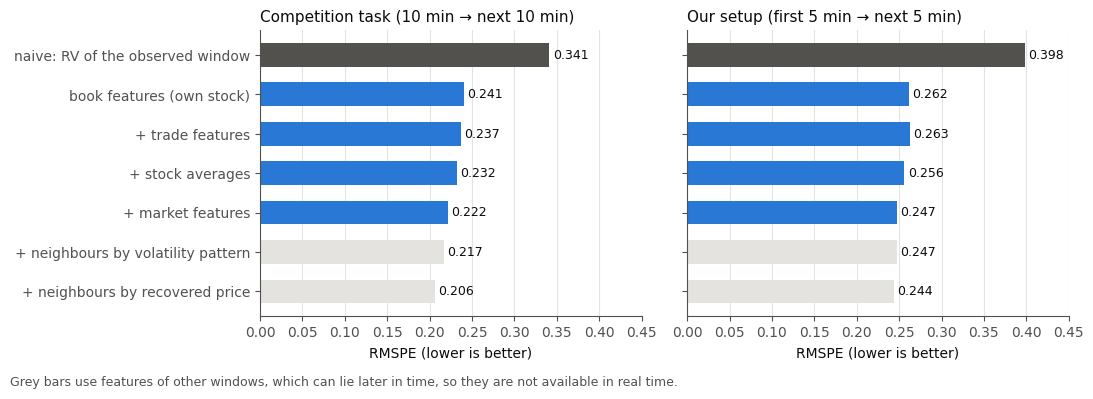

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (title, t) in zip(axes, [("Competition task (10 min → next 10 min)", comp_table),
                                 ("Our setup (first 5 min → next 5 min)", five_table)]):
    ypos = np.arange(len(t))[::-1]
    colors = [GRID if other else BLUE for other in t["uses other windows"]]
    colors[0] = INK2
    ax.barh(ypos, t.RMSPE, color=colors, height=0.6)
    for yy, v in zip(ypos, t.RMSPE):
        ax.text(v + 0.004, yy, f"{v:.3f}", va="center", fontsize=9, color=INK)
    ax.set_yticks(ypos, t.model)
    ax.set_xlim(0, 0.45)
    ax.set_xlabel("RMSPE (lower is better)")
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
fig.text(0.01, -0.03, "Grey bars use features of other windows, which can lie later in time, so they are not "
         "available in real time.", fontsize=9, color=INK2)
fig.tight_layout()
fig.savefig(FIGS / "volatility_ladder.png", bbox_inches="tight")
plt.show()

## 5. Does volatility help the spread and return models?

We take notebook 04's baseline (same 47 inputs, same gradient boosting settings) and add the volatility features one group at a time. Folds and rows are the same as in section 4.

The first row matches notebook 04 (spread R² 0.348), so the setup is consistent.

In [6]:
HGB = dict(learning_rate=0.05, max_iter=300, max_leaf_nodes=31, min_samples_leaf=200,
           l2_regularization=1.0, random_state=0)
groups = [("notebook 04 baseline inputs", [], False),
          ("+ volatility features (own stock)", book5 + trade5, False),
          ("+ market volatility features", book5 + trade5 + mkt5, False),
          ("+ neighbour features", book5 + trade5 + mkt5 + nnvol5 + nnpx5, True)]
rows, ext_oof = [], {}
for target, name in [("y_spread", "change in average spread"), ("y_price", "5-minute return")]:
    for label, extra, other in groups:
        oof = np.zeros(len(five))
        for k in range(5):
            tr, va = folds_five != k, folds_five == k
            Xa, Xb = fold_features(five[tr], five[va])
            if extra:
                Xa = pd.concat([Xa.reset_index(drop=True), five.loc[tr, extra].reset_index(drop=True)], axis=1)
                Xb = pd.concat([Xb.reset_index(drop=True), five.loc[va, extra].reset_index(drop=True)], axis=1)
            yt = five.loc[tr, target].to_numpy()
            ok = np.isfinite(yt)
            oof[va] = HistGradientBoostingRegressor(**HGB).fit(Xa[ok], yt[ok]).predict(Xb)
        ext_oof[(target, label)] = oof
        rows.append({"target": name, "inputs": label, "R2": r2(five[target], oof), "uses other windows": other})
ext_table = pd.DataFrame(rows)
ext_table.to_csv(METRICS / "volatility_added_to_targets.csv", index=False)
display(ext_table.round(4))

,target,inputs,R2,uses other windows
0,change in average spread,notebook 04 baseline inputs,0.3484,False
1,change in average spread,+ volatility features (own stock),0.3514,False
2,change in average spread,+ market volatility features,0.3530,False
3,change in average spread,+ neighbour features,0.3661,True
4,5-minute return,notebook 04 baseline inputs,0.0406,False
5,5-minute return,+ volatility features (own stock),0.0400,False
6,5-minute return,+ market volatility features,0.0476,False
7,5-minute return,+ neighbour features,0.0496,True


For the spread, volatility features barely help (0.348 → 0.353). The spread model already has first-half RV and spread history, which carry most of the same information. The neighbour features help more, but they use other windows (section 3) so we don't count that.

For returns, the stock's own volatility features do nothing, but the market volatility features help: R² goes from 0.041 to 0.048. We think this is because volatility tells the trees how much to trust the other signals, e.g. the same order book imbalance probably means a bigger move when the whole market is volatile.

Our best return model in notebook 04 is ridge (R² 0.061), so this only shows the features have some information. We still need to add them to the ridge and LightGBM models.

## 6. Volatility and the trading rule

The rule from notebook 04 buys at the ask at second 300 and sells at the bid at second 599, so a trade only makes money if the price moves more than the spread. A volatility forecast tells us beforehand how big the move will probably be, so it should help find windows where trading even has a chance.

We call a window a "hit" if the absolute five-minute move is bigger than the spread at second 299. The hit rate is the best a perfect direction call could do. The spread by itself already predicts hits (narrow spreads are easier to beat), so the question is whether forecast volatility adds anything on top. We use the forecasts from the best section 4 model that doesn't use other windows ("+ market features").

share of hits overall: 0.72


,ranking,AUC for picking hits
0,narrower spread,0.678
1,higher forecast volatility,0.461
2,forecast volatility ÷ spread,0.720


volatility third,low,middle,high
spread group,,,
1,0.87,0.90,0.94
2,0.79,0.85,0.91
3,0.75,0.84,0.90
4,0.71,0.79,0.87
5,0.67,0.76,0.86
6,0.62,0.72,0.83
7,0.56,0.67,0.80
8,0.49,0.63,0.77
9,0.42,0.57,0.74


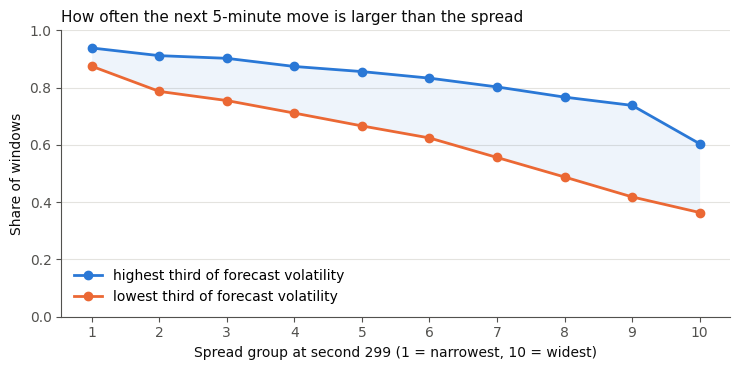

In [7]:
from sklearn.metrics import roc_auc_score

a = five[["stock_id", "time_id", "y_price", "q_299"]].copy()
a["vol_forecast"] = five_oof["+ market features"]
a["spread_bps"] = a.q_299 * 1e4
a["hit"] = a.y_price.abs() > a.spread_bps
print(f"share of hits overall: {a.hit.mean():.2f}")

auc = pd.DataFrame({"ranking": ["narrower spread", "higher forecast volatility", "forecast volatility ÷ spread"],
                    "AUC for picking hits": [roc_auc_score(a.hit, -a.spread_bps), roc_auc_score(a.hit, a.vol_forecast),
                                             roc_auc_score(a.hit, a.vol_forecast / a.spread_bps)]})
display(auc.round(3))

# Two-way table: spread group (1 = narrowest) by forecast-volatility third within that spread group
a["spread group"] = pd.qcut(a.spread_bps, 10, labels=range(1, 11))
a["volatility third"] = a.groupby("spread group", observed=True).vol_forecast.transform(
    lambda s: pd.qcut(s, 3, labels=False)).map({0: "low", 1: "middle", 2: "high"})
hits = a.pivot_table(index="spread group", columns="volatility third", values="hit", observed=True)[["low", "middle", "high"]]
hits.to_csv(METRICS / "volatility_vs_trading_cost.csv")
display(hits.round(2))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(1, 11)
for col, color, label in [("high", BLUE, "highest third of forecast volatility"),
                          ("low", ORANGE, "lowest third of forecast volatility")]:
    ax.plot(x, hits[col], color=color, lw=2, marker="o", ms=6, label=label)
ax.fill_between(x, hits["low"], hits["high"], color=BLUE, alpha=0.08, lw=0)
ax.set_xticks(x)
ax.set_ylim(0, 1)
ax.set_xlabel("Spread group at second 299 (1 = narrowest, 10 = widest)")
ax.set_ylabel("Share of windows")
ax.set_title("How often the next 5-minute move is larger than the spread", loc="left", fontsize=11, color=INK)
ax.legend(frameon=False, loc="lower left")
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGS / "volatility_vs_trading_cost.png", bbox_inches="tight")
plt.show()

On its own, forecast volatility is actually a bad predictor of hits (AUC below 0.5), because volatile stocks also tend to have wide spreads. But within the same spread group it separates windows pretty clearly. In the wider half of the spread groups, the most volatile third has a hit rate about 20–30 points higher than the least volatile third. Ranking by forecast volatility / spread does better than the spread alone (AUC 0.72 vs 0.68).

So one idea for notebook 04's rule is to only trade when forecast volatility is high compared to the spread. That's not the same as the spread-forecast filter we tried in notebook 04 (which didn't help). Hit rate is only an upper bound though, since we'd still need to get the direction right. To know if it actually helps after costs we'd need to run the full simulation, with the threshold picked on inner folds like in notebook 04.

## 7. Summary

- The competition approach works on our data. RMSPE goes from 0.341 (naive) to 0.222 using only the window itself and the other stocks in it. Neighbours bring it to 0.206 but use future information. On Kaggle's private leaderboard we got 0.2455 without neighbours and 0.2186 with them (winner ≈ 0.19), so the neighbours matter even more on new data.
- Five-minute volatility is very predictable: R² ≈ 0.87 on log RV, compared with ≈ 0.35 for the spread change and ≈ 0.06 for returns.
- Market-wide volatility is the most useful extra input, for volatility and a bit for returns (R² 0.041 → 0.048).
- Volatility relative to the spread shows where trading could pay. For windows with similar spreads, the most volatile third beats the spread much more often than the least volatile third.

Things to try next:

1. Add a forecast volatility / spread filter to the trading rule and test it with notebook 04's nested folds and bootstrap.
2. Add the market volatility features to the ridge and LightGBM return models from notebook 04.
3. Scale the return forecast by forecast volatility instead of trading on the raw return.
4. Score the final volatility model once on the benchmark windows, like in notebook 04.